# 03b – Class Imbalance Analysis
**Stage 2 – TASK 03** · Owner: Phong

**Input:** `data/processed/research_data.csv` (only the `is_late` label and order status are used).
**Output:** figures → `outputs/figures/`, tables → `outputs/tables/`, written findings → `docs/class_imbalance_findings_eng.md`.

Goal: assess the imbalance between Late (1) and Not Late (0) over **all orders with a valid label**, and recommend suitable evaluation metrics.
**Not done here:** SMOTE, resampling, class weighting, model training.
(Related monthly prevalence is discussed in the TASK 02 notebook, `03_late_delivery_eda.ipynb`, EDA03.)

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ---------- CONFIG ----------
def find_project_root(start=None):
    # Walk up from the current directory until data/processed/research_data.csv is found
    # (works when run from the repo root or from notebooks/).
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "research_data.csv").exists():
            return p
    raise FileNotFoundError("Could not find data/processed/research_data.csv from " + str(start))

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "research_data.csv"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
EXPECTED_SHAPE = (99441, 34)   # official research_data.csv in the repo
SAVE_OUTPUTS = True            # False = display only, do not write files
MIN_N = 100                    # groups with valid_orders < MIN_N are flagged "low n"
VERY_LOW_N = 30                # groups with valid_orders < 30 are flagged "very low n"
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
C_LATE, C_OK, C_FLAG = "#d62728", "#4c72b0", "#bdbdbd"
# ----------------------------

if SAVE_OUTPUTS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def save_table(df_, name):
    if SAVE_OUTPUTS:
        df_.to_csv(TABLE_DIR / f"{name}.csv", index=True)

## 1. Load data & define the analysis sample

In [2]:
print("PROJECT_ROOT:", PROJECT_ROOT)
print("Reading data from:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
if df.shape != EXPECTED_SHAPE:
    print(f"WARNING: shape differs from the official file {EXPECTED_SHAPE}. Check the research_data.csv version before using these results.")
assert df["order_id"].is_unique, "Duplicate order_id -> data is no longer at order level"

# ---- Analysis sample: orders with a valid is_late label (same definition as TASK 02) ----
mask_valid = df["is_late"].notna()
assert set(df.loc[mask_valid, "is_late"].unique()) <= {0, 1}, "is_late has values outside {0, 1}"
df_valid = df.loc[mask_valid].copy()
df_valid["is_late"] = df_valid["is_late"].astype(int)

n_total, n_valid = len(df), len(df_valid)
n_late = int(df_valid["is_late"].sum()); n_not_late = n_valid - n_late
OVERALL_RATE = df_valid["is_late"].mean()
print(f"Total orders: {n_total:,} | valid label: {n_valid:,} | Late: {n_late:,} | Not Late: {n_not_late:,}")
print(f"Orders without a label (excluded): {n_total - n_valid:,}")

sample_table = pd.DataFrame({
    "Item": ["Total orders", "Orders with a valid is_late label (analysis sample)", "   - Late (1)", "   - Not Late (0)", "Orders without a label (excluded)"],
    "Orders": [n_total, n_valid, n_late, n_not_late, n_total - n_valid],
})
sample_table["% of all orders"] = (sample_table["Orders"] / n_total * 100).round(2)
save_table(sample_table.set_index("Item"), "imb00_sample_selection")
sample_table

PROJECT_ROOT: C:\Users\ADMIN\OneDrive\Desktop\Group5_STAT3013.R11
Reading data from: C:\Users\ADMIN\OneDrive\Desktop\Group5_STAT3013.R11\data\processed\research_data.csv
Shape: (99441, 34)
Total orders: 99,441 | valid label: 96,470 | Late: 6,534 | Not Late: 89,936
Orders without a label (excluded): 2,971


,Item,Orders,% of all orders
0,Total orders,99441,100.00
1,Orders with a valid is_late label (analysis sa...,96470,97.01
2,- Late (1),6534,6.57
3,- Not Late (0),89936,90.44
4,Orders without a label (excluded),2971,2.99


## B1. Counts, percentages and imbalance ratio

In [3]:
y = df_valid["is_late"]
counts = y.value_counts().reindex([0, 1])
n0, n1 = int(counts[0]), int(counts[1])
N = n0 + n1
majority_label, minority_label = (0, 1) if n0 >= n1 else (1, 0)
n_maj, n_min = max(n0, n1), min(n0, n1)

imb_ratio = n_maj / n_min
prevalence = n1 / N          # share of the positive class (Late) in this sample
baseline_acc = n_maj / N     # accuracy when always predicting the majority class

class_table = pd.DataFrame({
    "Class": ["Not Late (0)", "Late (1)", "Total (valid label)"],
    "Orders": [n0, n1, N],
    "Share %": [n0 / N * 100, n1 / N * 100, 100.0],
}).set_index("Class").round(2)
save_table(class_table, "imb01_class_distribution")
display(class_table)

stats = pd.Series({
    "Majority class": "Not Late (0)" if majority_label == 0 else "Late (1)",
    "Minority class": "Late (1)" if minority_label == 1 else "Not Late (0)",
    "Imbalance ratio (majority : minority)": f"{imb_ratio:.2f} : 1",
    "Imbalance ratio (minority / majority)": f"{n_min / n_maj:.4f}",
    "Prevalence of Late": f"{prevalence:.4%}",
    "Accuracy when always predicting the majority class": f"{baseline_acc:.4%}",
}, name="Value")
save_table(stats.to_frame(), "imb02_imbalance_stats")
stats.to_frame()

,Orders,Share %
Class,,
Not Late (0),89936,93.23
Late (1),6534,6.77
Total (valid label),96470,100.00


,Value
Majority class,Not Late (0)
Minority class,Late (1)
Imbalance ratio (majority : minority),13.76 : 1
Imbalance ratio (minority / majority),0.0727
Prevalence of Late,6.7731%
Accuracy when always predicting the majority class,93.2269%


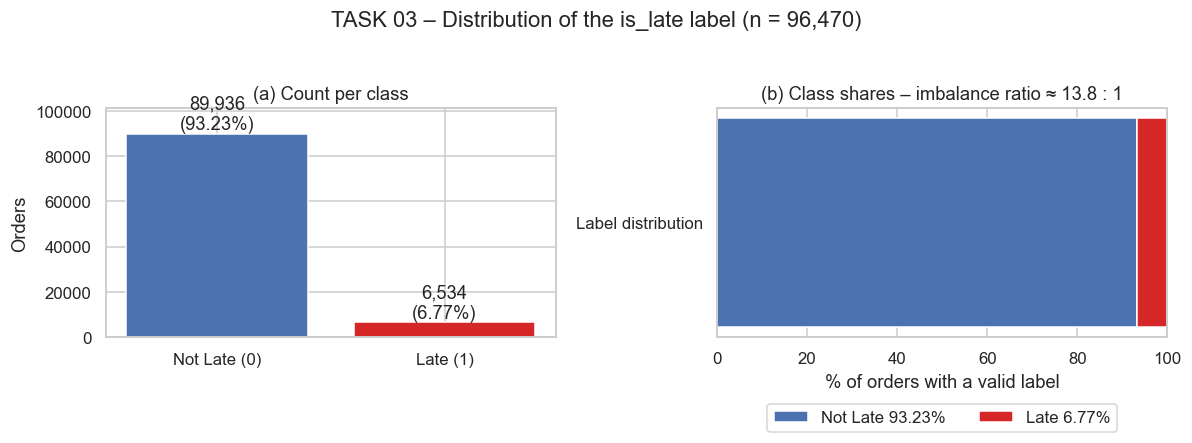

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# (a) Count plot
bars = axes[0].bar(["Not Late (0)", "Late (1)"], [n0, n1], color=[C_OK, C_LATE])
for b, v in zip(bars, [n0, n1]):
    axes[0].annotate(f"{v:,}\n({v/N:.2%})", (b.get_x() + b.get_width()/2, v), ha="center", va="bottom")
axes[0].set_ylim(0, N * 1.05); axes[0].set_ylabel("Orders"); axes[0].set_title("(a) Count per class")

# (b) 100% stacked bar
axes[1].barh(["Label distribution"], [n0 / N * 100], color=C_OK, label=f"Not Late {n0/N:.2%}")
axes[1].barh(["Label distribution"], [n1 / N * 100], left=[n0 / N * 100], color=C_LATE, label=f"Late {n1/N:.2%}")
axes[1].set_xlim(0, 100); axes[1].set_xlabel("% of orders with a valid label")
axes[1].set_title(f"(b) Class shares – imbalance ratio ≈ {imb_ratio:.1f} : 1")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=2)

fig.suptitle(f"TASK 03 – Distribution of the is_late label (n = {N:,})", y=1.03)
plt.tight_layout(); save_fig(fig, "imb01_class_distribution"); plt.show()

**B1 findings:** 89,936 Not Late orders (93.23%) versus 6,534 Late orders (6.77%) → **imbalance ratio ≈ 13.76 : 1** (about 14 on-time orders for every late one). The class of interest (Late) is the minority class. No severity label (mild/moderate/severe) is assigned because there is no agreed criterion or cited convention; the ratio is reported directly.

## B2. Why Accuracy is misleading (arithmetic example, no model trained)
Consider a trivial classifier that always predicts **Not Late**. Its confusion matrix follows directly from the class counts (no model is fitted):

In [5]:
# Constant classifier: always predicts Not Late (class 0) -> Late is the positive class
TP, FN = 0, n1          # catches no late order
FP, TN = 0, n0

def safe_div(a, b):
    return a / b if b > 0 else np.nan

acc = (TP + TN) / N
prec = safe_div(TP, TP + FP)      # undefined (0/0): the Late class is never predicted
rec = safe_div(TP, TP + FN)
f1 = 0.0 if (TP == 0) else 2 * TP / (2 * TP + FP + FN)

cm = pd.DataFrame([[TN, FP], [FN, TP]],
                  index=["Actual: Not Late", "Actual: Late"],
                  columns=["Predicted: Not Late", "Predicted: Late"])
display(cm)

baseline = pd.Series({"Accuracy": acc, "Precision (Late)": prec, "Recall (Late)": rec, "F1 (Late)": f1,
                      "ROC-AUC (no discrimination)": 0.5, "Average Precision (constant scorer) = prevalence": prevalence},
                     name="Always-'Not Late'").round(4)
save_table(baseline.to_frame(), "imb03_trivial_classifier")
baseline.to_frame()

,Predicted: Not Late,Predicted: Late
Actual: Not Late,89936,0
Actual: Late,6534,0


,Always-'Not Late'
Accuracy,0.9323
Precision (Late),NaN
Recall (Late),0.0000
F1 (Late),0.0000
ROC-AUC (no discrimination),0.5000
Average Precision (constant scorer) = prevalence,0.0677


Accuracy = **93.23%**, yet Recall for the Late class = **0%**, F1 = 0 and Precision is undefined → the model "looks excellent" but **detects no late order at all**. This is the *accuracy paradox*.

### B2.1 Illustration of Precision under different TPR/FPR scenarios
From the definitions, with prevalence π = 6.77% and given recall (TPR) and FPR:
`Precision = TPR·π / (TPR·π + FPR·(1−π))`, `Accuracy = TPR·π + (1−FPR)·(1−π)`.
The scenarios below are **pure-formula assumptions** (both TPR and FPR change between rows), not model results.

In [6]:
scenarios = [(0.50, 0.10), (0.70, 0.20), (0.80, 0.20), (0.90, 0.30)]
rows = []
for tpr, fpr in scenarios:
    tp = tpr * prevalence; fp = fpr * (1 - prevalence)
    prec_s = tp / (tp + fp)
    acc_s = tp + (1 - fpr) * (1 - prevalence)
    f1_s = 2 * prec_s * tpr / (prec_s + tpr)
    rows.append({"Recall (TPR)": tpr, "FPR": fpr, "Accuracy": acc_s, "Precision (Late)": prec_s, "F1 (Late)": f1_s,
                 "Orders flagged per 1,000 orders": round((tp + fp) * 1000)})
scenario_df = pd.DataFrame(rows).round(3)
save_table(scenario_df.set_index("Recall (TPR)"), "imb04_illustrative_scenarios")
scenario_df

,Recall (TPR),FPR,Accuracy,Precision (Late),F1 (Late),"Orders flagged per 1,000 orders"
0,0.5,0.1,0.873,0.266,0.348,127
1,0.7,0.2,0.793,0.203,0.314,234
2,0.8,0.2,0.800,0.225,0.351,241
3,0.9,0.3,0.714,0.179,0.299,341


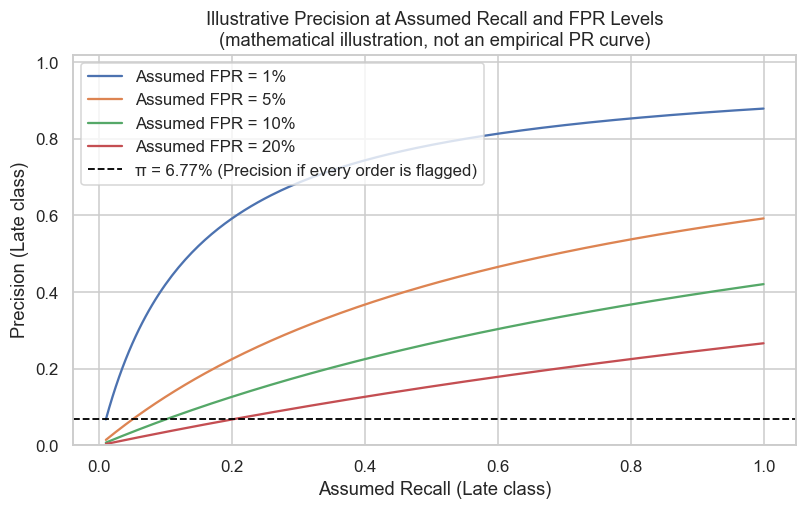

In [7]:
# Mathematical illustration: Precision at ASSUMED Recall and FPR levels (depends only on prevalence).
# This is NOT an empirical PR curve of any model.
recall = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for fpr_ in [0.01, 0.05, 0.10, 0.20]:
    precision_ = recall * prevalence / (recall * prevalence + fpr_ * (1 - prevalence))
    ax.plot(recall, precision_, label=f"Assumed FPR = {fpr_:.0%}")
ax.axhline(prevalence, color="black", ls="--", lw=1.2, label=f"π = {prevalence:.2%} (Precision if every order is flagged)")
ax.set_xlabel("Assumed Recall (Late class)"); ax.set_ylabel("Precision (Late class)")
ax.set_ylim(0, 1.02)
ax.set_title("Illustrative Precision at Assumed Recall and FPR Levels\n(mathematical illustration, not an empirical PR curve)")
ax.legend()
plt.tight_layout(); save_fig(fig, "imb02_illustrative_precision"); plt.show()

**Baseline reference table (instead of a combined ROC/PR chart – the two plots have different axis meanings, so they are not drawn together):**

In [8]:
baseline_ref = pd.DataFrame({
    "Metric": ["ROC-AUC", "Average Precision (AP)"],
    "Reference level": ["0.5 (scorer with no discrimination)", f"{prevalence:.4f} = prevalence of the evaluated set (constant scorer)"],
    "Note": ["Does not depend on prevalence",
             "Depends on the Late share of the evaluation set itself; one random ranking does not necessarily give an AP exactly equal to prevalence. 0.0677 is only the prevalence of the full labelled sample, not a fixed value for every set."],
}).set_index("Metric")
save_table(baseline_ref, "imb05_metric_baselines")
baseline_ref

,Reference level,Note
Metric,,
ROC-AUC,0.5 (scorer with no discrimination),Does not depend on prevalence
Average Precision (AP),0.0677 = prevalence of the evaluated set (cons...,Depends on the Late share of the evaluation se...


## B3. Effect of imbalance on metrics & recommended evaluation metrics
| Metric | Effect when Late is only ~6.8% | Recommended role |
|---|---|---|
| **Accuracy** | Dominated by the majority class; always predicting "Not Late" already gives **93.23%** → does not reflect the ability to catch late orders | Report only as a side figure, **not** as the main metric |
| **Precision (Late)** | The share of correct alerts among flagged orders; sensitive to low prevalence (B2.1: Recall 80%, FPR 20% → Precision ≈ 22.5%). Converting this into cost needs business assumptions | Shows how many alerts are right vs wrong |
| **Recall (Late)** | Not inflated by the size of the majority class; shows what % of late orders are caught | Measures missed late orders – the main goal of early prediction |
| **F1 (Late)** | Balances Precision and Recall of the Late class; = 0 for the constant classifier | Summary at one decision threshold |
| **ROC-AUC** | Ranking quality across all thresholds; a high ROC-AUC can still come with low Precision and many false alerts when the Late class is rare, so AP should also be reported | **Recommended** – compare models' ranking ability |
| **Average Precision (AP)** | Focuses on the Late class; the reference level is the prevalence of the evaluation set. AP is not the same as the area under the PR curve computed with the trapezoidal rule | **Recommended** – main metric for the Late class, together with the Precision–Recall curve |

**Recommended metric set:** main metric **Average Precision (AP)** (plus ROC-AUC); report Precision / Recall / F1 of the Late class at a threshold chosen on validation data according to the objective and cost, together with the **confusion matrix**; Accuracy for reference only. When reporting AP, compare it with the prevalence of the **evaluation set itself** (≈ 0.068 holds only for the full labelled sample), not with 0.5.

**Limitations of Accuracy as the main metric**
1. Dominated by the majority class: the constant classifier already reaches 93.23%.
2. Does not distinguish the two error types (missed late orders vs false alerts); the cost of each needs business assumptions.
3. Depends on the classification threshold; the threshold should be chosen on validation data according to the objective and cost, not by default.
4. The 93.23% floor makes any improvement look tiny (e.g. 95% is only 1.8 points higher).
5. Prevalence changes over time (≈19% in 2018-03 vs ≈1.2% in 2018-06 – see EDA03), so Accuracy is not directly comparable across periods.

**Evaluation design (provisional; to be finalised during ML design, not done in this task):** because the goal is to predict future orders, the provisional design is a time-based split (train → validation → test); thresholds chosen on validation; the test set is not rebalanced.

## B4. Checks & output listing

In [9]:
assert n0 + n1 == len(df_valid) == n_valid
assert abs(prevalence - OVERALL_RATE) < 1e-12
print(f"OK – N = {N:,}, Late = {n1:,} ({prevalence:.2%}), Not Late = {n0:,} ({n0/N:.2%}), imbalance ratio = {imb_ratio:.2f}:1")
if SAVE_OUTPUTS:
    print("Tables:", sorted(p.name for p in TABLE_DIR.glob("*.csv")))
    print("Figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

OK – N = 96,470, Late = 6,534 (6.77%), Not Late = 89,936 (93.23%), imbalance ratio = 13.76:1
Tables: ['eda00_sample_selection.csv', 'eda00_temporal_feature_reconciliation.csv', 'eda01_late_distribution.csv', 'eda02_late_rate_by_weekday.csv', 'eda03_late_rate_by_month.csv', 'eda04_late_rate_by_state.csv', 'eda05_late_rate_by_distance_group.csv', 'eda06_freight_by_late.csv', 'eda07_estimated_window_by_late.csv', 'eda07_late_rate_by_estimated_window_group.csv', 'eda07_promised_days_by_late.csv', 'eda08_delay_split.csv', 'eda08_delay_summary.csv', 'eda_summary.csv', 'imb00_sample_selection.csv', 'imb01_class_distribution.csv', 'imb02_imbalance_stats.csv', 'imb03_trivial_classifier.csv', 'imb04_illustrative_scenarios.csv', 'imb05_metric_baselines.csv']
Figures: ['eda01_late_distribution.png', 'eda02_late_rate_by_weekday.png', 'eda03_late_rate_by_month.png', 'eda04_late_rate_by_state.png', 'eda05_late_rate_by_distance_group.png', 'eda06_freight_by_late.png', 'eda07_estimated_window_by_late.p